<a href="https://colab.research.google.com/github/danicardemar-alt/Final-Project-Presentation-/blob/main/Final_project_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Comparing Antibiotic Resistance Genes in Untreated Wastewater, Treated Wastewater Effluent and Surface Water Microbiomes Using Genomic Sequencing

Daniela Cardenas


Download softwares and upload data table

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
!pip install python-docx

import io
from google.colab import files
import docx

print("Please upload your .docx file:")
uploaded = files.upload()


Please upload your .docx file:


Saving Data_Sheet_1.docx to Data_Sheet_1 (2).docx


Extracting S1 and S4 data sets from published data

In [12]:
s1_data = [
    [cell.text.strip() for cell in row.cells]
    for row in doc.tables[0].rows
]

s4_data = [
    [cell.text.strip() for cell in row.cells]
    for row in doc.tables[6].rows
]

# Convert the extracted data into DataFrames
s1_df = pd.DataFrame(s1_data)
s4_df = pd.DataFrame(s4_data)

# Preview both tables
print("TABLE S1")
display(s1_df)

TABLE S1


,0,1,2,3,4,5,6
0,Sample ID,Trimmed read pairs,Total no. of ORFs,No. of ARG-like ORFs,Total percentage of ARG-like ORFs (%),Size of metagenome (MB),No. of unique ARG subtypes
1,H1,"3,202,560","329,801",512,0.16,144,188
2,H2,"2,697,598","418,086",416,0.1,183,164
3,H3,"3,270,686","447,152",488,0.11,201,191
4,H4,"2,694,623","415,717",327,0.09,187,133
5,H5,"2,937,862","349,143",415,0.12,156,164
6,WW,"2,669,915","436,195",308,0.07,172,121
7,TW1,"1,928,883","326,339",48,0.01,123,22
8,TW2,"2,190,396","344,840",51,0.01,136,27
9,BH,"2,476,019","298,008",42,0.01,108,16


Simplifying S1 data set for analysis

In [13]:
s1_richness = s1_df.iloc[1:, [0, 6]].copy()

s1_richness.columns = ["Sample_ID", "ARG_Richness"]

s1_richness["ARG_Richness"] = pd.to_numeric(
    s1_richness["ARG_Richness"])

environment_groups = {
    "H1": "Untreated wastewater",
    "H2": "Untreated wastewater",
    "H3": "Untreated wastewater",
    "H4": "Untreated wastewater",
    "H5": "Untreated wastewater",
    "WW": "Untreated wastewater",
    "TW1": "Treated wastewater effluent",
    "TW2": "Treated wastewater effluent",
    "BH": "Surface water",
    "BI": "Surface water",
    "BB": "Surface water",
    "MA": "Surface water",
    "RA": "Surface water"}

s1_richness["Environment"] = (
    s1_richness["Sample_ID"].map(environment_groups))

display(s1_richness)

,Sample_ID,ARG_Richness,Environment
1,H1,188,Untreated wastewater
2,H2,164,Untreated wastewater
3,H3,191,Untreated wastewater
4,H4,133,Untreated wastewater
5,H5,164,Untreated wastewater
6,WW,121,Untreated wastewater
7,TW1,22,Treated wastewater effluent
8,TW2,27,Treated wastewater effluent
9,BH,16,Surface water
10,BI,15,Surface water


Organizing S4 data set

In [14]:
display(s4_df)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,,Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB),Abundance of ARG types (coverage x/GB)
1,,Wastewaters,Wastewaters,Wastewaters,Wastewaters,Wastewaters,Wastewaters,Treated effluent,Treated effluent,Surface waters,Surface waters,Surface waters,Surface waters,Surface waters
2,ARG type,H1,H2,H3,H4,H5,WW,TW1,TW2,BH,BI,BB,MA,RA
3,Aminoglycoside,104293.76,4758.84,25851.09,2352.15,9239.73,648.72,270.38,716.15,252.22,1069.92,1502.23,14200.09,371.57
4,Bacitracin,565.65,214.62,13979.89,53.96,240.71,19.49,0.00,0.00,0.00,400.56,0.00,0.00,0.00
5,Beta-lactam \n(class A),279150.17,7762.85,28285.12,825.23,1512.45,674.10,8.07,13.46,0.00,0.00,55.21,0.00,0.00
6,Beta-lactam \n(class B),234.61,396.11,161.76,135.66,545.63,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,Beta-lactam \n(class C),300.62,161.33,23602.22,81.74,26161.48,40.75,0.00,0.00,0.00,0.00,9.90,0.00,0.00
8,Beta-lactam \n(class D),3586.44,744.75,1796.35,187.46,7133.39,120.73,68.30,24.28,148.09,25.33,61.85,0.00,0.00
9,Bleomycin,10.01,8.21,107.18,14.59,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Simplifying the S4 table for analysis

In [19]:
sample_ids = s4_df.iloc[2, 1:14].tolist()

arg_types = s4_df.iloc[3:25, 0].tolist()

abundance_values = s4_df.iloc[3:25, 1:14].apply(
    pd.to_numeric)

normalized_abundance = abundance_values.copy()
normalized_abundance.columns = sample_ids
normalized_abundance.index = arg_types

display(normalized_abundance)

,H1,H2,H3,H4,H5,WW,TW1,TW2,BH,BI,BB,MA,RA
Aminoglycoside,104293.76,4758.84,25851.09,2352.15,9239.73,648.72,270.38,716.15,252.22,1069.92,1502.23,14200.09,371.57
Bacitracin,565.65,214.62,13979.89,53.96,240.71,19.49,0.00,0.00,0.00,400.56,0.00,0.00,0.00
Beta-lactam \n(class A),279150.17,7762.85,28285.12,825.23,1512.45,674.10,8.07,13.46,0.00,0.00,55.21,0.00,0.00
Beta-lactam \n(class B),234.61,396.11,161.76,135.66,545.63,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Beta-lactam \n(class C),300.62,161.33,23602.22,81.74,26161.48,40.75,0.00,0.00,0.00,0.00,9.90,0.00,0.00
Beta-lactam \n(class D),3586.44,744.75,1796.35,187.46,7133.39,120.73,68.30,24.28,148.09,25.33,61.85,0.00,0.00
Bleomycin,10.01,8.21,107.18,14.59,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Chloramphenicol,5060.78,550.77,458.15,227.43,548.71,100.38,0.00,0.00,0.00,0.00,30.06,0.00,0.00
Multidrug resistant efflux pumps,26738.65,7067.35,396018.54,3249.77,26134.55,3127.17,858.45,1009.16,847.42,696.12,9169.52,232.64,191.62
Fosfomycin,1532.62,28.91,0.00,0.00,47.76,20.79,0.00,0.00,0.00,59.20,0.00,0.00,0.00


Verifying calculations match up with totals in S1

In [18]:
published_totals = pd.to_numeric(s4_df.iloc[25, 1:14])

published_totals.index = sample_ids

calculated_totals = normalized_abundance.sum(axis=0)

comparison = pd.DataFrame({
    "Calculated total": calculated_totals,
    "Published total": published_totals})

comparison["Difference"] = (
    comparison["Calculated total"] - comparison["Published total"])

display(comparison)

,Calculated total,Published total,Difference
H1,520764.21,520764.23,-2.000000e-02
H2,42065.72,42065.72,7.275958e-12
H3,521875.10,521875.10,5.820766e-11
H4,14056.01,14056.03,-2.000000e-02
H5,80222.44,80222.43,1.000000e-02
WW,7913.74,7913.74,0.000000e+00
TW1,1944.23,1944.22,1.000000e-02
TW2,3440.98,3440.97,1.000000e-02
BH,1736.68,1736.69,-1.000000e-02
BI,3325.18,3325.17,1.000000e-02


Calculate relative abundance for each ARG category

In [20]:
relative_abundance = (
    normalized_abundance.div(
        normalized_abundance.sum(axis=0), axis=1
    ) * 100)

display(relative_abundance.round(2))

,H1,H2,H3,H4,H5,WW,TW1,TW2,BH,BI,BB,MA,RA
Aminoglycoside,20.03,11.31,4.95,16.73,11.52,8.20,13.91,20.81,14.52,32.18,10.59,71.40,46.73
Bacitracin,0.11,0.51,2.68,0.38,0.30,0.25,0.00,0.00,0.00,12.05,0.00,0.00,0.00
Beta-lactam \n(class A),53.60,18.45,5.42,5.87,1.89,8.52,0.42,0.39,0.00,0.00,0.39,0.00,0.00
Beta-lactam \n(class B),0.05,0.94,0.03,0.97,0.68,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Beta-lactam \n(class C),0.06,0.38,4.52,0.58,32.61,0.51,0.00,0.00,0.00,0.00,0.07,0.00,0.00
Beta-lactam \n(class D),0.69,1.77,0.34,1.33,8.89,1.53,3.51,0.71,8.53,0.76,0.44,0.00,0.00
Bleomycin,0.00,0.02,0.02,0.10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Chloramphenicol,0.97,1.31,0.09,1.62,0.68,1.27,0.00,0.00,0.00,0.00,0.21,0.00,0.00
Multidrug resistant efflux pumps,5.13,16.80,75.88,23.12,32.58,39.52,44.15,29.33,48.80,20.93,64.66,1.17,24.10
Fosfomycin,0.29,0.07,0.00,0.00,0.06,0.26,0.00,0.00,0.00,1.78,0.00,0.00,0.00


Verify all relative abundance calculations add up to 100

In [21]:
percentage_totals = relative_abundance.sum(axis=0)

display(percentage_totals.round(2))

,0
H1,100.0
H2,100.0
H3,100.0
H4,100.0
H5,100.0
WW,100.0
TW1,100.0
TW2,100.0
BH,100.0
BI,100.0


Display S1 richness focused table

In [22]:
display(s1_richness)

,Sample_ID,ARG_Richness,Environment
1,H1,188,Untreated wastewater
2,H2,164,Untreated wastewater
3,H3,191,Untreated wastewater
4,H4,133,Untreated wastewater
5,H5,164,Untreated wastewater
6,WW,121,Untreated wastewater
7,TW1,22,Treated wastewater effluent
8,TW2,27,Treated wastewater effluent
9,BH,16,Surface water
10,BI,15,Surface water


Mean, median, min, max and count values for richness evaluation

In [26]:
richness_summary = s1_richness.groupby("Environment")[
    "ARG_Richness"
].agg(["count", "mean", "median", "min", "max"])

display(richness_summary.round(2))

,count,mean,median,min,max
Environment,,,,,
Surface water,5,18.40,15.0,4,51
Treated wastewater effluent,2,24.50,24.5,22,27
Untreated wastewater,6,160.17,164.0,121,191


Dot plot showing ARG richness between our 3 aquatic environments

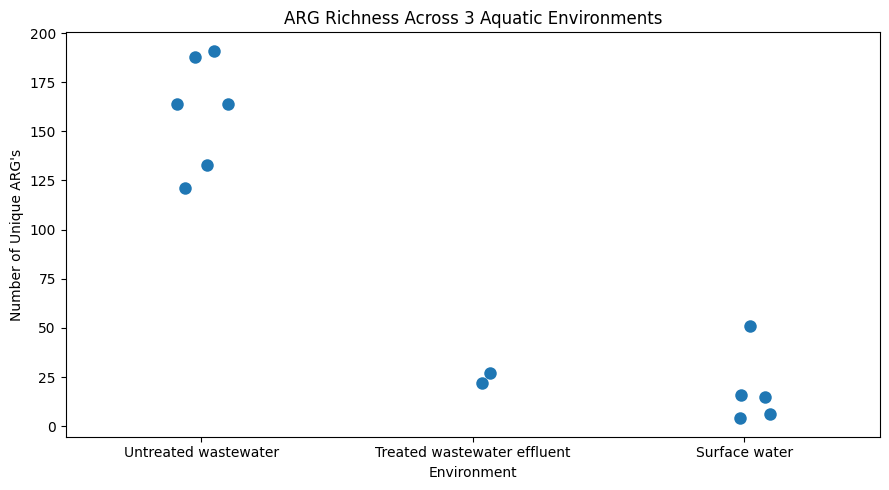

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.stripplot(
    data=s1_richness,
    x="Environment",
    y="ARG_Richness",
    jitter=True,
    size=9)

plt.title("ARG Richness Across 3 Aquatic Environments")
plt.xlabel("Environment")
plt.ylabel("Number of Unique ARG's")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Summarizing ARG normalized abundance to aquatic environment

In [29]:
sample_environments = s1_richness.set_index(
    "Sample_ID"
)["Environment"]

abundance_summary = normalized_abundance.T.copy()

abundance_summary["Environment"] = (
    sample_environments)

abundance_by_environment = abundance_summary.groupby(
    "Environment"
).mean(numeric_only=True)

display(abundance_by_environment.round(2))

,Aminoglycoside,Bacitracin,Beta-lactam \n(class A),Beta-lactam \n(class B),Beta-lactam \n(class C),Beta-lactam \n(class D),Bleomycin,Chloramphenicol,Multidrug resistant efflux pumps,Fosfomycin,...,MLSB,Polymyxin,Quinolone,Rifampin,Streptogramin,Streptothricin,Sulfonamide,Tetracyline,Trimethoprim,Vancomycin
Environment,,,,,,,,,,,,,,,,,,,,,
Surface water,3479.21,80.11,11.04,0.00,1.98,47.05,0.00,6.01,2227.46,11.84,...,24.77,4.49,1980.01,1.80,0.0,0.00,44.47,35.80,27.61,0.00
Treated wastewater effluent,493.26,0.00,10.76,0.00,0.00,46.29,0.00,0.00,933.80,0.00,...,25.35,0.00,380.54,265.88,0.0,0.00,58.02,58.20,0.00,414.42
Untreated wastewater,24524.05,2512.39,53034.99,245.63,8391.36,2261.52,23.33,1157.70,77056.00,271.68,...,543.89,1342.11,6859.50,450.62,5.1,29.34,14048.30,1841.08,1032.02,332.55


Heat map for each ARG and its normalized abundance in a specific aquatice environment

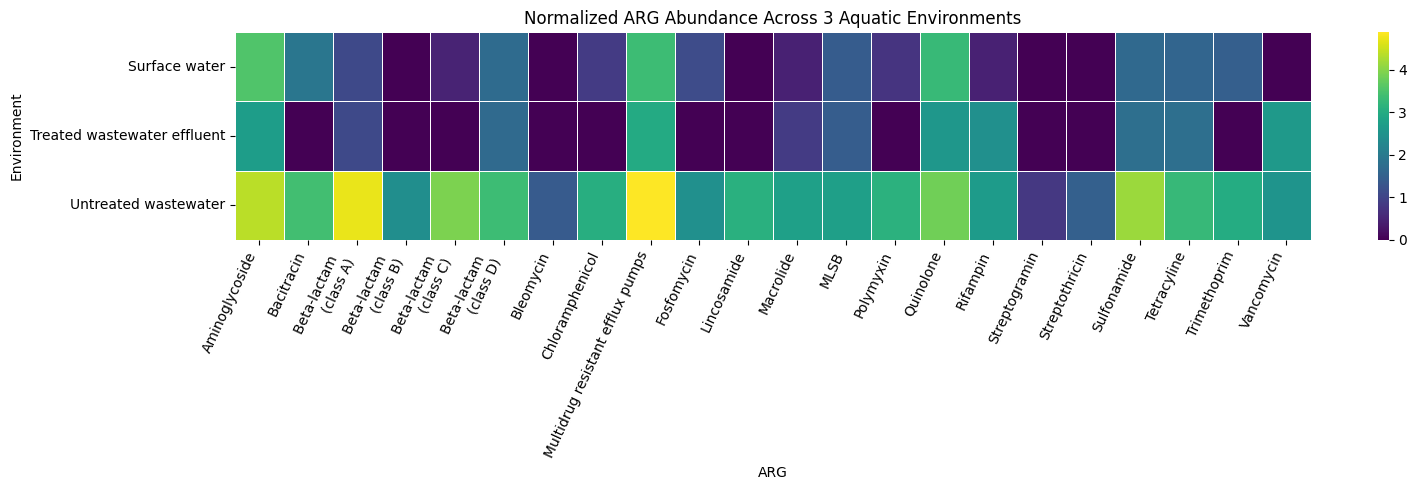

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

log_abundance = np.log10(abundance_by_environment + 1)

plt.figure(figsize=(16, 5))

sns.heatmap(
    log_abundance,
    cmap="viridis",
    linewidths=0.5,
    annot=False
)

plt.title("Normalized ARG Abundance Across 3 Aquatic Environments")
plt.xlabel("ARG")
plt.ylabel("Environment")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

Summarizing relative ARG abundance in 3 aquatic environments

In [32]:
relative_summary = relative_abundance.T.copy()

relative_summary["Environment"] = sample_environments

relative_by_environment = relative_summary.groupby(
    "Environment"
).mean(numeric_only=True)

display(relative_by_environment.round(2))

,Aminoglycoside,Bacitracin,Beta-lactam \n(class A),Beta-lactam \n(class B),Beta-lactam \n(class C),Beta-lactam \n(class D),Bleomycin,Chloramphenicol,Multidrug resistant efflux pumps,Fosfomycin,...,MLSB,Polymyxin,Quinolone,Rifampin,Streptogramin,Streptothricin,Sulfonamide,Tetracyline,Trimethoprim,Vancomycin
Environment,,,,,,,,,,,,,,,,,,,,,
Surface water,35.08,2.41,0.08,0.00,0.01,1.95,0.00,0.04,31.93,0.36,...,0.17,0.03,25.81,0.01,0.00,0.00,1.09,0.51,0.42,0.00
Treated wastewater effluent,17.36,0.00,0.40,0.00,0.00,2.11,0.00,0.00,36.74,0.00,...,0.80,0.00,15.35,9.07,0.00,0.00,1.90,2.00,0.00,14.09
Untreated wastewater,12.12,0.70,15.63,0.44,6.45,2.43,0.02,0.99,32.17,0.11,...,1.21,0.52,10.22,0.11,0.03,0.03,3.70,5.20,0.61,0.58


Heat map for each ARG and its relative abundance in a specific aquatice environment

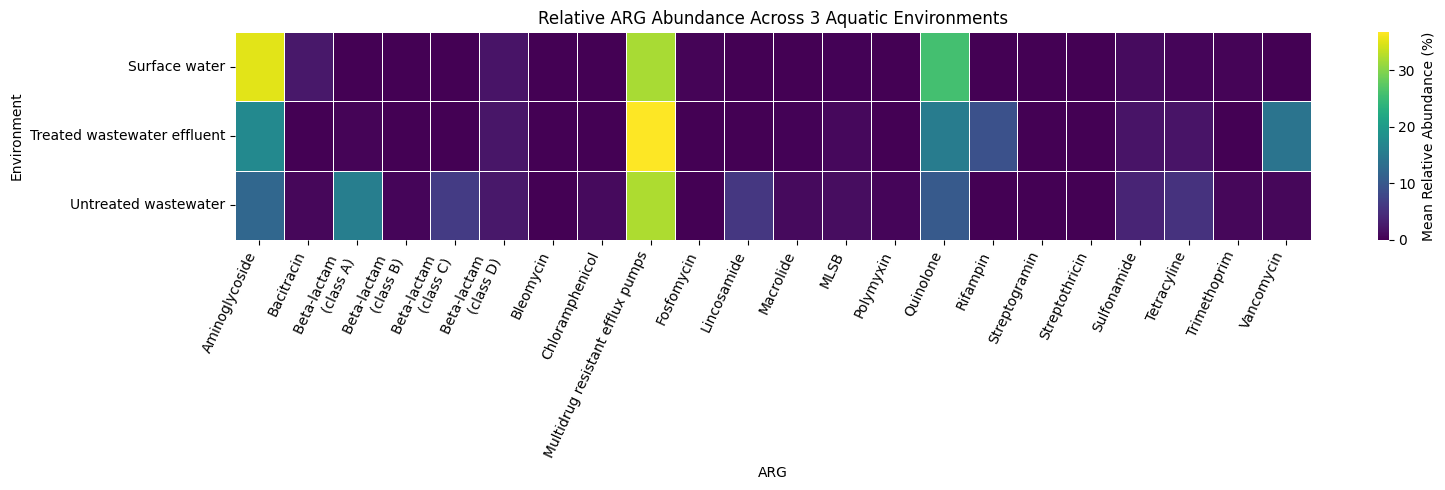

In [33]:
plt.figure(figsize=(16, 5))

sns.heatmap(
    relative_by_environment,
    cmap="viridis",
    linewidths=0.5,
    annot=False,
    cbar_kws={"label": "Mean Relative Abundance (%)"})

plt.title("Relative ARG Abundance Across 3 Aquatic Environments")
plt.xlabel("ARG")
plt.ylabel("Environment")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

Comparing top 5 most abundant ARGs in relative and normalized abundance

In [34]:
normalized_long = abundance_by_environment.reset_index().melt(
    id_vars="Environment",
    var_name="ARG_Category",
    value_name="Mean_Normalized_Abundance")

top5_normalized = (
    normalized_long
    .sort_values(
        ["Environment", "Mean_Normalized_Abundance"],
        ascending=[True, False])
    .groupby("Environment")
    .head(5))

display(top5_normalized)

,Environment,ARG_Category,Mean_Normalized_Abundance
0,Surface water,Aminoglycoside,3479.206000
24,Surface water,Multidrug resistant efflux pumps,2227.464000
42,Surface water,Quinolone,1980.012000
3,Surface water,Bacitracin,80.112000
15,Surface water,Beta-lactam \n(class D),47.054000
25,Treated wastewater effluent,Multidrug resistant efflux pumps,933.805000
1,Treated wastewater effluent,Aminoglycoside,493.265000
64,Treated wastewater effluent,Vancomycin,414.420000
43,Treated wastewater effluent,Quinolone,380.545000
46,Treated wastewater effluent,Rifampin,265.875000


In [35]:
relative_long = relative_by_environment.reset_index().melt(
    id_vars="Environment",
    var_name="ARG_Category",
    value_name="Mean_Relative_Abundance")

top5_relative = (
    relative_long
    .sort_values(
        ["Environment", "Mean_Relative_Abundance"],
        ascending=[True, False])
    .groupby("Environment")
    .head(5))

display(top5_relative)

,Environment,ARG_Category,Mean_Relative_Abundance
0,Surface water,Aminoglycoside,35.083402
24,Surface water,Multidrug resistant efflux pumps,31.930584
42,Surface water,Quinolone,25.809441
3,Surface water,Bacitracin,2.409253
15,Surface water,Beta-lactam \n(class D),1.945014
25,Treated wastewater effluent,Multidrug resistant efflux pumps,36.740709
1,Treated wastewater effluent,Aminoglycoside,17.359588
43,Treated wastewater effluent,Quinolone,15.346383
64,Treated wastewater effluent,Vancomycin,14.087749
46,Treated wastewater effluent,Rifampin,9.070655


### Exporting Figures and Tables as PNG files

In [36]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Create a directory to store the outputs
os.makedirs('exported_outputs', exist_ok=True)

# -----------------------------------------------------
# 1. Recreate and Save Figure 1: ARG Richness Stripplot
# -----------------------------------------------------
plt.figure(figsize=(9, 5))
sns.stripplot(
    data=s1_richness,
    x="Environment",
    y="ARG_Richness",
    jitter=True,
    size=9
)
plt.title("ARG Richness Across 3 Aquatic Environments")
plt.xlabel("Environment")
plt.ylabel("Number of Unique ARG's")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('exported_outputs/fig1_arg_richness_stripplot.png', dpi=300)
plt.close()

# -----------------------------------------------------
# 2. Recreate and Save Figure 2: Normalized Abundance Heatmap
# -----------------------------------------------------
log_abundance = np.log10(abundance_by_environment + 1)
plt.figure(figsize=(16, 5))
sns.heatmap(
    log_abundance,
    cmap="viridis",
    linewidths=0.5,
    annot=False
)
plt.title("Normalized ARG Abundance Across 3 Aquatic Environments")
plt.xlabel("ARG")
plt.ylabel("Environment")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.savefig('exported_outputs/fig2_normalized_abundance_heatmap.png', dpi=300)
plt.close()

# -----------------------------------------------------
# 3. Recreate and Save Figure 3: Relative Abundance Heatmap
# -----------------------------------------------------
plt.figure(figsize=(16, 5))
sns.heatmap(
    relative_by_environment,
    cmap="viridis",
    linewidths=0.5,
    annot=False,
    cbar_kws={"label": "Mean Relative Abundance (%)"}
)
plt.title("Relative ARG Abundance Across 3 Aquatic Environments")
plt.xlabel("ARG")
plt.ylabel("Environment")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.savefig('exported_outputs/fig3_relative_abundance_heatmap.png', dpi=300)
plt.close()

# -----------------------------------------------------
# Helper function to render a Pandas DataFrame as a PNG table
# -----------------------------------------------------
def save_table_as_png(df, filepath, title):
    fig, ax = plt.subplots(figsize=(10, len(df) * 0.6 + 1.5))
    ax.axis('off')

    # Styled table
    tbl = ax.table(
        cellText=df.round(2).values,
        colLabels=df.columns,
        rowLabels=df.index if not isinstance(df.index, pd.RangeIndex) else None,
        cellLoc='center',
        loc='center'
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(11)
    tbl.scale(1.2, 1.5)

    # Style headers
    for key, cell in tbl.get_celld().items():
        if key[0] == 0 or key[1] == -1:
            cell.set_text_props(weight='bold')
            cell.set_facecolor('#eaeaea')

    plt.title(title, weight='bold', fontsize=14, pad=10)
    plt.tight_layout()
    plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.close()

# -----------------------------------------------------
# 4. Save Tables as PNGs
# -----------------------------------------------------
save_table_as_png(richness_summary, 'exported_outputs/table_richness_summary.png', "ARG Richness Summary by Environment")
save_table_as_png(top5_normalized, 'exported_outputs/table_top5_normalized.png', "Top 5 Most Abundant ARGs (Normalized Abundance)")
save_table_as_png(top5_relative, 'exported_outputs/table_top5_relative.png', "Top 5 Most Abundant ARGs (Relative Abundance)")

print("All figures and tables successfully saved as PNGs in the 'exported_outputs' directory:")
!ls -la exported_outputs

All figures and tables successfully saved as PNGs in the 'exported_outputs' directory:
total 1864
drwxr-xr-x 2 root root   4096 Nov 18 05:38 .
drwxr-xr-x 1 root root   4096 Nov 18 05:38 ..
-rw-r--r-- 1 root root 104040 Nov 18 05:38 fig1_arg_richness_stripplot.png
-rw-r--r-- 1 root root 392130 Nov 18 05:38 fig2_normalized_abundance_heatmap.png
-rw-r--r-- 1 root root 410139 Nov 18 05:38 fig3_relative_abundance_heatmap.png
-rw-r--r-- 1 root root 100211 Nov 18 05:38 table_richness_summary.png
-rw-r--r-- 1 root root 452933 Nov 18 05:38 table_top5_normalized.png
-rw-r--r-- 1 root root 426408 Nov 18 05:38 table_top5_relative.png


In [37]:
import shutil
from google.colab import files

# Zip the exported_outputs directory
zip_filename = 'exported_figures_and_tables'
shutil.make_archive(zip_filename, 'zip', 'exported_outputs')

# Download the zip file to your computer
print("Downloading your zip file...")
files.download(f"{zip_filename}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>